In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [3]:
#numerically model mean MTD time evolution in the quasiequilibrium limit

In [225]:
#MTD parameters
sigma = 1
omega = 0.1 #we really care about the limit as this goes to zero but a small finite value should suffice
deltaT = 10

#simulation parameter
T = 1
#k_B = 1 assumed here



well volume = 750.4765054731595


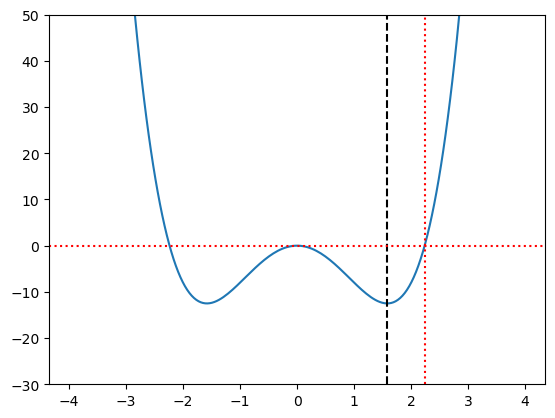

In [226]:
#system
class double_well_1:
    def __init__(self, A,B):
        self.A = A
        self.B = B

    def f1(self, x):
        return self.A*(x**4 - self.B*x**2)

    def wellbottom(self):
        return (self.B/2)**(1/2)

    def well_volume(self,x):
        volume = 0
        for Fi in self.f1(x):
            if Fi<0:
                volume -= Fi
        return volume
    
    def wall_equals_middle(self):
        return np.sqrt(self.B)

dw1 = double_well_1(2,5)

padfactor = 2.5
x = np.linspace(-padfactor*dw1.wellbottom(), padfactor*dw1.wellbottom(),200)
F = dw1.f1(x)

plt.plot(x,F)
plt.axvline(dw1.wellbottom(), linestyle="dashed", color="black")
#plt.axvline(-dw1.wellbottom(), linestyle="dashed", color="black")
plt.axvline(dw1.wall_equals_middle(), linestyle="dotted", color="red")
plt.axhline(0, linestyle="dotted", color="red")
well_vol = dw1.well_volume(x)
print(f"well volume = {well_vol}")

plt.ylim(-30,50)

lim_ind = np.where(x>-dw1.wall_equals_middle())[0][0]
#print(lim_ind)


well volume = 19.900000000000013


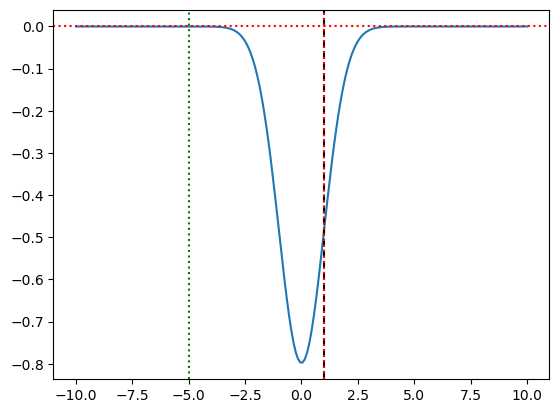

In [227]:
#system
class gaussian_well_1:
    def __init__(self, A,B):
        self.A = A
        self.B = B

    def f1(self, x):
        return -self.A*(1/np.sqrt(2*np.pi*self.B**2))*np.exp(-0.5 * (x / self.B)**2)

    def stdev(self):
        return self.B

    def well_volume(self,x):
        volume = 0
        for Fi in self.f1(x):
            if Fi<0:
                volume -= Fi
        return volume
    
    def wall_equals_middle(self):
        return 1

dw1 = gaussian_well_1(2,1)

padfactor = 10
x = np.linspace(-padfactor*dw1.stdev(), padfactor*dw1.stdev(),200)
F = dw1.f1(x)

plt.plot(x,F)
plt.axvline(dw1.stdev(), linestyle="dashed", color="black")
plt.axvline(dw1.wall_equals_middle(), linestyle="dotted", color="red")
plt.axhline(0, linestyle="dotted", color="red")
well_vol = dw1.well_volume(x)
print(f"well volume = {well_vol}")

#plt.ylim(-30,50)

lim_ind = np.where(x>-5*dw1.stdev())[0][0]
plt.axvline(x[lim_ind], linestyle="dotted", color="green")

1.0


(0.0, 1.0)

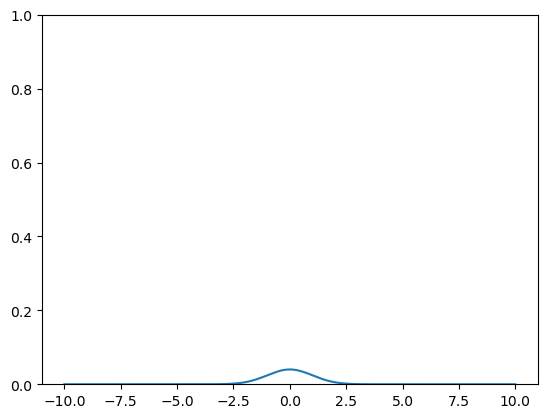

In [228]:
gaussian = norm.pdf(x, loc=0, scale=sigma)
gaussian /= np.sum(gaussian)

plt.plot(x,gaussian)
print(np.sum(gaussian))
plt.ylim(0,1)


9950 rounds


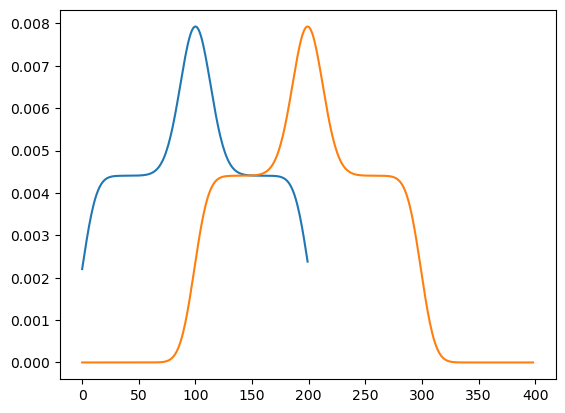

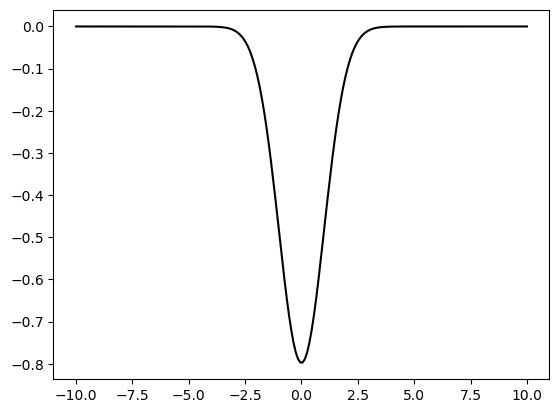

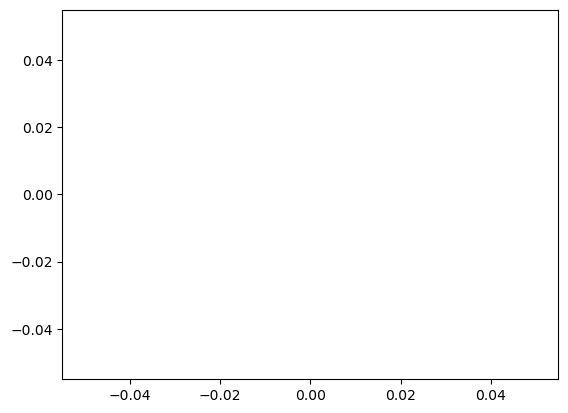

In [231]:
V = np.zeros(len(F))

rmse = []

nrounds = 50*round(well_vol/omega)
print(f"{nrounds} rounds")
for t in range(nrounds):
    #for an even number of frames the convolution is shifted off by half a bin. 
    # For an odd number of frames it should already be symmetrical so the symmetrization should do nothing

    plt.plot(np.convolve(gaussian, np.exp(-V/deltaT)*np.exp(-(F+V)/T)/np.sum(np.exp(-(F+V)/T)),mode="same"))
    plt.plot(np.convolve(gaussian, np.exp(-V/deltaT)*np.exp(-(F+V)/T)/np.sum(np.exp(-(F+V)/T)),mode="full"))
    plt.show()
    break

    convolution_halfshifted = np.convolve(gaussian, np.exp(-V/deltaT)*np.exp(-(F+V)/T)/np.sum(np.exp(-(F+V)/T)),mode="same")
    convolution_symmetrized = (convolution_halfshifted+convolution_halfshifted[::-1])/2
    V += omega*convolution_symmetrized
    if t%100==0:
        plt.plot(x, F+V*(T+deltaT)/deltaT, color=(t/nrounds,0.8,0))
        F_norm = F[lim_ind:-lim_ind]+T*np.log(np.sum(np.exp(-F[lim_ind:-lim_ind]/T)))
        fV = -V*(T+deltaT)/deltaT
        fV_norm = fV[lim_ind:-lim_ind]+T*np.log(np.sum(np.exp(-fV[lim_ind:-lim_ind]/T)))
        #plt.plot(x[lim_ind:-lim_ind], fV_norm)
        rmse.append(np.sqrt(np.mean((F_norm - fV_norm)**2)))

#plt.plot(x[lim_ind:-lim_ind], F_norm)

plt.plot(x,F, color="black")
#plt.ylim(0, 100)

plt.show()
plt.plot(rmse)

In [230]:
TODO: ignoring the edges, make a plot of the RMSE convergence time and asymptotic error as a function of sigma. 
The former plot should increase with sigma (and be undefined at large nonconvergent sigma)
The latter plot should be flat until sigma hits the well sigma, and then it should increase with sigma.

SyntaxError: invalid syntax (2349398736.py, line 1)